### Task 1.2: Create an agent

Make your first agent using Amazon Nova Lite.

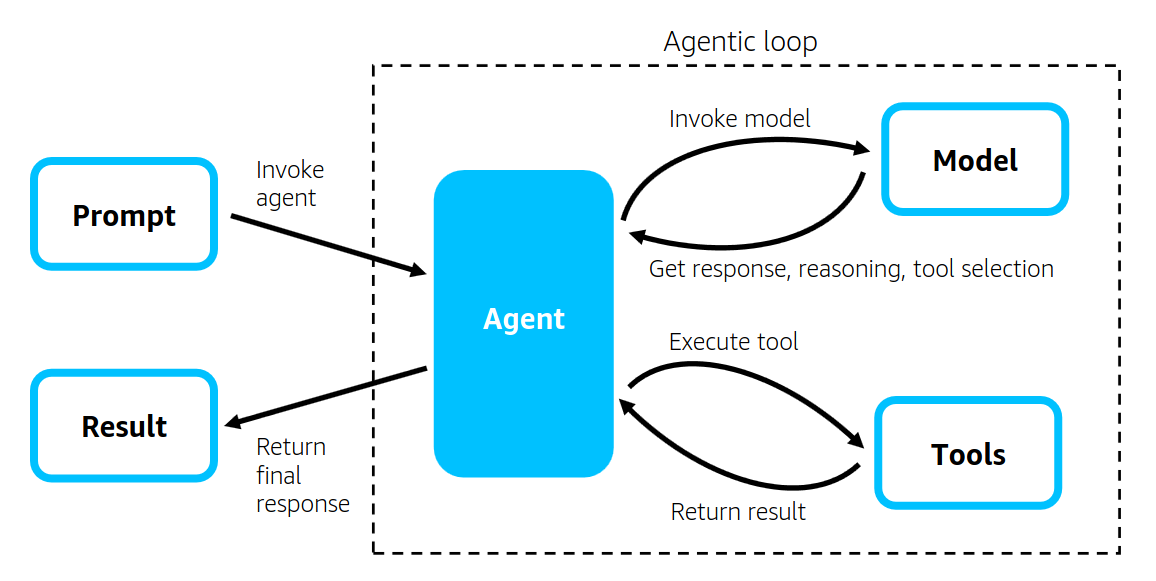

In [1]:
from IPython.display import Image
Image(filename='images/agent.png', width='70%')

The agentic loop represents an AI agent's decision-making cycle, where it receives a prompt, processes it through a model, selects and uses appropriate tools, and returns results. This continuous loop allows the agent to interact with prompts and tools while leveraging the model's capabilities to produce meaningful responses.

By default, an **Agent** object uses the Amazon Bedrock model provider with the Anthropic Claude 4 model. Other model providers including Anthropic, OpenAI, and LiteLLM can be used with Strands Agents. In this lab you use the Amazon Bedrock model provider with specific models in specific regions, so you must use the **BedrockModel** class with a boto3 session.

1. To create a model, run the following cell:

In [2]:
import boto3
from strands.models import BedrockModel

use1_session = boto3.Session(region_name = "us-east-1")
usw2_session = boto3.Session(region_name = "us-west-2")

nova_lite = BedrockModel(model_id="amazon.nova-lite-v1:0", boto_session=use1_session)

2. To create a Strands agent, run the following cell:

In [3]:
from strands import Agent

# Create an agent
basic_agent = Agent(
    model = nova_lite
)

3. To invoke an agent, instructing it to write a file to your directory, run the following cell:

In [4]:
# Invoke an agent
response = basic_agent("Write a file called flights.csv to my file system")
print(response)

To create a `flights.csv` file, you can use Python to write the file to your file system. Below is a sample code snippet that will create a CSV file with some sample flight data. You can customize the content as per your needs.

Here's how you can do it:

```python
import csv

# Sample data for flights
flights = [
    ["Flight Number", "Departure", "Arrival", "Duration", "Airline"],
    ["UA123", "JFK", "LAX", "3h 30m", "United Airlines"],
    ["AA456", "ORD", "MIA", "2h 15m", "American Airlines"],
    ["DL789", "DFW", "ATL", "1h 45m", "Delta Air Lines"],
    ["WN012", "PDX", "LAS", "1h 30m", "Southwest Airlines"]
]

# Define the file name
file_name = "flights.csv"

# Writing to csv file
with open(file_name, mode='w', newline='') as file:
    writer = csv.writer(file)
    writer.writerows(flights)

print(f"File '{file_name}' has been created successfully.")
```

When you run this script, it will create a `flights.csv` file in the same directory as your script with the following content

The agent you just used has no tools, leverages no MCPs, and does not interface with any other agents. 

It is effectively just the base Amazon Nova Lite model, not taking advantage of the agentic optimizations offered by Strands Agents. It gives you instructions on how to perform an action, rather than taking the action itself.

### Task 1.3: Create a coding assistant by adding tools

Add read, write, and file execution using Strands Agents built-in tools.

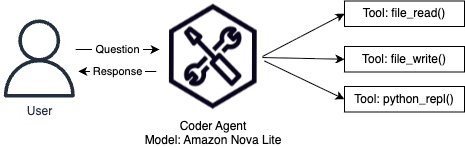

In [5]:
from IPython.display import Image
Image(filename='images/coder.png')

The true strength of Strands Agents is unlocked by using tools. Tools allow agents to interact with external systems, access data, and manipulate environments.

Strands offers built-in tools to get started with extending your agent past simple text generation.

4. To add the **file_read** built-in tool and a **system_prompt**, creating a more-complex agent that can help you code, run the following cell:

In [6]:
from strands_tools import file_read

agent_with_tool = Agent(
    model = nova_lite,
    system_prompt = """You are a helpful assistant.
    You can read from the local file system to answer questions
    """,
    tools = [file_read]
)

5. To invoke the file reading agent, run the following cell:

In [7]:
# Invoke an agent
response = agent_with_tool("""I need to create a flights csv object using the schema provided in ./project/flights-schema.csv.
What fields are required?""")
print(response)

<thinking>The User needs to know the required fields in the CSV schema located at./project/flights-schema.csv. I will use the file_read tool in view mode to read the contents of the schema file and then identify the required fields.</thinking>

Tool #1: file_read


╔═══════════════════════════════════════ 📄 flights-schema.csv ═══════════════════════════════════════╗
║                                                                                                     ║
║    1 Field,Type,Required,Pattern/Format,Description,Constraints                                     ║
║    2 FlightNumber,string,No,^[A-Z]{2}[0-9]{3,4}$,Airline code followed by numbers (e.g. AA123),     ║
║    3 Origin,string,Yes,^[A-Za-z\s\-]+$,City name of origin,min length: 2; max length: 50            ║
║    4 Destination,string,Yes,^[A-Za-z\s\-]+$,City name of destination,min length: 2; max length: 50  ║
║    5 DepartureTime,string,Yes,date-time,ISO 8601 date-time format,                                  ║
║    6 Arrival,string,Yes,date-time,ISO 8601 date-time format,                                        ║
║                                                                                                     ║
╚═════════════════════════════════════════════════════════════════════════════════════════════════════╝

<thinking>I have retrieved the content of the flights-schema.csv file and identified the required fields. I will now extract and present the required fields to the User.</thinking>

Required fields in the CSV schema are:
- Origin
- Destination
- DepartureTime
- Arrival

These fields are marked as "Yes" under the "Required" column in the schema.<thinking>I have retrieved the content of the flights-schema.csv file and identified the required fields. I will now extract and present the required fields to the User.</thinking>

Required fields in the CSV schema are:
- Origin
- Destination
- DepartureTime
- Arrival

These fields are marked as "Yes" under the "Required" column in the schema.



When you add tools to an agent, agent responses become verbose, as it walks you through its tool selection process.

6. To override the default *SlidingWindowConveresationManager* by using the **callback_handler** parameter, run the following cell:

In [8]:
agent_with_tool = Agent(
    model = nova_lite,
    system_prompt = """You are a helpful assistant.
    You can read from the local file system to answer questions
    """,
    tools = [file_read],
    callback_handler=None
)

7. To learn more about your projects data requirements from a spec document, run the following cell:

In [9]:
response = agent_with_tool("""I need to create a flights csv table using the schema provided in ./project/flights-schema.csv.
What fields are required?""")
print(response)

╔═══════════════════════════════════════ 📄 flights-schema.csv ═══════════════════════════════════════╗
║                                                                                                     ║
║    1 Field,Type,Required,Pattern/Format,Description,Constraints                                     ║
║    2 FlightNumber,string,No,^[A-Z]{2}[0-9]{3,4}$,Airline code followed by numbers (e.g. AA123),     ║
║    3 Origin,string,Yes,^[A-Za-z\s\-]+$,City name of origin,min length: 2; max length: 50            ║
║    4 Destination,string,Yes,^[A-Za-z\s\-]+$,City name of destination,min length: 2; max length: 50  ║
║    5 DepartureTime,string,Yes,date-time,ISO 8601 date-time format,                                  ║
║    6 Arrival,string,Yes,date-time,ISO 8601 date-time format,                                        ║
║                                                                                                     ║
╚═════════════════════════════════════════════════════════════════════════════════════════════════════╝

<thinking>The schema file lists all the fields for the flights CSV table, including whether they are required or not. I will now summarize the required fields.</thinking>

Based on the schema, the required fields for the flights CSV table are:

1. **Origin** - City name of origin
2. **Destination** - City name of destination
3. **DepartureTime** - ISO 8601 date-time format
4. **Arrival** - ISO 8601 date-time format





When tools perform write actions, they will typically request consent. Because we are not using the terminal, we can bypass this by setting.

8. To set the **BYPASS_TOOL_CONENT** environment variable, run the following cell.

In [10]:
import os

os.environ["BYPASS_TOOL_CONSENT"] = "true"

You can include multiple tools in an agent.

9. To add the built-in **file_write** tool to an agent, run the following cell:

In [11]:
from strands_tools import file_write

coder_agent = Agent(
    model = nova_lite,
    system_prompt = """You are a helpful assistant.
    You can read from the local file system to answer questions 
    and write to it when asked.
    """,
    tools = [file_read, file_write],
)


10. To create a file of mock users, run the following cell:

In [12]:
coder_agent("Use the schema provided in the file /home/ec2-user/environment/project/flights-schema.csv and write 5 flight rows in csv to a file called /home/ec2-user/environment/project/flights.csv")

<thinking>To complete the task, I need to read the schema from the provided CSV file to understand the structure and then write 5 flight rows to a new CSV file. I will use the 'file_read' tool to read the schema and then write the 5 rows using the 'file_write' tool. I'll generate the content based on the schema I read.</thinking>

Tool #1: file_read


╔═══════════════════════════════════════ 📄 flights-schema.csv ═══════════════════════════════════════╗
║                                                                                                     ║
║    1 Field,Type,Required,Pattern/Format,Description,Constraints                                     ║
║    2 FlightNumber,string,No,^[A-Z]{2}[0-9]{3,4}$,Airline code followed by numbers (e.g. AA123),     ║
║    3 Origin,string,Yes,^[A-Za-z\s\-]+$,City name of origin,min length: 2; max length: 50            ║
║    4 Destination,string,Yes,^[A-Za-z\s\-]+$,City name of destination,min length: 2; max length: 50  ║
║    5 DepartureTime,string,Yes,date-time,ISO 8601 date-time format,                                  ║
║    6 Arrival,string,Yes,date-time,ISO 8601 date-time format,                                        ║
║                                                                                                     ║
╚═════════════════════════════════════════════════════════════════════════════════════════════════════╝

<thinking>Now that I have the schema, I can create 5 rows of flight data to write to the new CSV file. I'll ensure the data conforms to the schema for each field. I will use the 'file_write' tool to create the new file.</thinking>


Tool #2: file_write


╔════════════════ File Write Operation ════════════════╗
║                                                      ║
║ Path: /home/ec2-user/environment/project/flights.csv ║
║ Size: 369 characters                                 ║
║                                                      ║
╚══════════════════════════════════════════════════════╝

╔═════════════════════════════ Write Successful ══════════════════════════════╗
║ File written successfully to /home/ec2-user/environment/project/flights.csv ║
╚═════════════════════════════════════════════════════════════════════════════╝

<thinking>I have successfully written the 5 flight rows to the new CSV file as per the schema. I can now inform the User that the task is completed.</thinking>

I have successfully written 5 flight rows to the new CSV file located at `/home/ec2-user/environment/project/flights.csv`. The file contains the following data:

```
FlightNumber,Origin,Destination,DepartureTime,Arrival
AA123,New York,Los Angeles,2023-10-01T10:00:00,2023-10-01T12:30:00
BB456,Chicago,Miami,2023-10-01T14:00:00,2023-10-01T17:00:00
CC789,San Francisco,Houston,2023-10-01T08:00:00,2023-10-01T10:45:00
DD012,Seattle,Denver,2023-10-01T11:00:00,2023-10-01T13:30:00
EE345,Boston,Dallas,2023-10-01T15:00:00,2023-10-01T17:45:00
```

AgentResult(stop_reason='end_turn', message={'role': 'assistant', 'content': [{'text': '<thinking>I have successfully written the 5 flight rows to the new CSV file as per the schema. I can now inform the User that the task is completed.</thinking>\n\nI have successfully written 5 flight rows to the new CSV file located at `/home/ec2-user/environment/project/flights.csv`. The file contains the following data:\n\n```\nFlightNumber,Origin,Destination,DepartureTime,Arrival\nAA123,New York,Los Angeles,2023-10-01T10:00:00,2023-10-01T12:30:00\nBB456,Chicago,Miami,2023-10-01T14:00:00,2023-10-01T17:00:00\nCC789,San Francisco,Houston,2023-10-01T08:00:00,2023-10-01T10:45:00\nDD012,Seattle,Denver,2023-10-01T11:00:00,2023-10-01T13:30:00\nEE345,Boston,Dallas,2023-10-01T15:00:00,2023-10-01T17:45:00\n```'}], 'metadata': {'usage': {'inputTokens': 1947, 'outputTokens': 342, 'totalTokens': 2289}, 'metrics': {'latencyMs': 2055, 'timeToFirstByteMs': 340}}, 'tracking_id': '924371b5-ea51-4391-a952-ccead5425f

<div style="background-color: rgba(231, 243, 237, 0.3); border: 1px solid #43A047; border-radius: 6px; padding: 15px; margin: 10px 0; color: #2E7D32; font-family: monospace; max-width: 100%; word-wrap: break-word; box-sizing: border-box;">
<strong>Example Output</strong>
<br><br>
<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"><span style="color: #008000; text-decoration-color: #008000">╔═════════════════════════════ </span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">Write Successful</span><span style="color: #008000; text-decoration-color: #008000"> ══════════════════════════════╗</span>
<span style="color: #008000; text-decoration-color: #008000">║</span> <span style="color: #008000; text-decoration-color: #008000; font-weight: bold">File written successfully to /home/ec2-user/environment/project/flights.csv</span> <span style="color: #008000; text-decoration-color: #008000">║</span>
<span style="color: #008000; text-decoration-color: #008000">╚═════════════════════════════════════════════════════════════════════════════╝</span>
</pre>
The flight rows have been successfully written in the specified file.
</div>

You can also invoke a tool directly, using the *tool* method of the agent.

11. To read the newly created csv file, run the following command:

In [13]:
coder_agent.tool.file_read(path="./project/flights.csv", mode="view")

╔═════════════════════════════ 📄 flights.csv ══════════════════════════════╗
║                                                                           ║
║    1 FlightNumber,Origin,Destination,DepartureTime,Arrival                ║
║    2 AA123,New York,Los Angeles,2023-10-01T10:00:00,2023-10-01T12:30:00   ║
║    3 BB456,Chicago,Miami,2023-10-01T14:00:00,2023-10-01T17:00:00          ║
║    4 CC789,San Francisco,Houston,2023-10-01T08:00:00,2023-10-01T10:45:00  ║
║    5 DD012,Seattle,Denver,2023-10-01T11:00:00,2023-10-01T13:30:00         ║
║    6 EE345,Boston,Dallas,2023-10-01T15:00:00,2023-10-01T17:45:00          ║
║                                                                           ║
╚═══════════════════════════════════════════════════════════════════════════╝

{'toolUseId': 'tooluse_file_read_904715769',
 'status': 'success',
 'content': [{'text': 'Content of ./project/flights.csv:\nFlightNumber,Origin,Destination,DepartureTime,Arrival\nAA123,New York,Los Angeles,2023-10-01T10:00:00,2023-10-01T12:30:00\nBB456,Chicago,Miami,2023-10-01T14:00:00,2023-10-01T17:00:00\nCC789,San Francisco,Houston,2023-10-01T08:00:00,2023-10-01T10:45:00\nDD012,Seattle,Denver,2023-10-01T11:00:00,2023-10-01T13:30:00\nEE345,Boston,Dallas,2023-10-01T15:00:00,2023-10-01T17:45:00'}]}

<div style="background-color: rgba(231, 243, 237, 0.3); border: 1px solid #43A047; border-radius: 6px; padding: 15px; margin: 10px 0; color: #2E7D32; font-family: monospace; max-width: 100%; word-wrap: break-word; box-sizing: border-box;">
<strong>Example Output</strong>
<br><br>
<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"><span style="color: #000080; text-decoration-color: #000080">╔════════════════════════════════ </span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">📄 flights.csv</span><span style="color: #000080; text-decoration-color: #000080"> ════════════════════════════════╗</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>                                                                                <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">1 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">FlightNumber,Origin,Destination,DepartureTime,Arrival</span><span style="background-color: #272822">                   </span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">2 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">AA321,Miami,Denver,2023-10-11T08:00:00Z,2023-10-11T11:00:00Z</span><span style="background-color: #272822">            </span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">3 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">BA654,Madrid,Barcelona,2023-10-12T14:00:00Z,2023-10-12T16:00:00Z</span><span style="background-color: #272822">        </span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">4 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">DL987,Phoenix,Salt Lake City,2023-10-13T10:00:00Z,2023-10-13T13:00:00Z</span><span style="background-color: #272822">  </span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">5 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">UA246,Orlando,Detroit,2023-10-14T15:00:00Z,2023-10-14T18:00:00Z</span><span style="background-color: #272822">         </span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>  <span style="color: #e3e3dd; text-decoration-color: #e3e3dd; background-color: #272822; font-weight: bold">  </span><span style="color: #656660; text-decoration-color: #656660; background-color: #272822">6 </span><span style="color: #f8f8f2; text-decoration-color: #f8f8f2; background-color: #272822">EK567,Bangkok,Ho Chi Minh City,2023-10-15T17:00:00Z,2023-10-15T20:00:00Z</span>  <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">║</span>                                                                                <span style="color: #000080; text-decoration-color: #000080">║</span>
<span style="color: #000080; text-decoration-color: #000080">╚════════════════════════════════════════════════════════════════════════════════╝</span>
</pre>
</div>


**Note:** If your **flight.csv** schema does not match the example or the file failed to create, your agent did not perform as expected and you should re-run the previous two cells.

12. To add another tool to the agent, **python_repl**, and have the agent use it to execute python code that validates whether the created user json file, run the following cell:

In [14]:
from strands_tools import python_repl
import csv
import os

coder_agent = Agent(
    model = nova_lite,
    system_prompt = """You are a helpful assistant.
    You can read from the local file system to answer questions 
    and write to it when asked.
    """,
    tools = [file_read, file_write, python_repl],
    callback_handler=None
)


FILE_PATH="/home/ec2-user/environment/project/flights.csv"

coder_agent.tool.python_repl(code=f"""
import csv
import os

def validate(file_path):
    try:
        # Check if file exists
        if not os.path.exists(file_path):
            return False, "File does not exist"
            
        # Try to read the CSV file
        with open(file_path, 'r', encoding='utf-8') as file:
            csv_reader = csv.reader(file)
            # Read header
            header = next(csv_reader)
            # Read one row to verify data
            first_row = next(csv_reader)
            return True, "CSV file is valid"
            
    except csv.Error as e:
        return False, f"CSV parsing error: {{str(e)}}"
    except Exception as e:
        return False, f"Validation error: {{str(e)}}"

result, message = validate("{FILE_PATH}")
print(f"Validation result: {{result}}")
print(f"Message: {{message}}")
""")


DEPRECATION WARNING: python_repl is deprecated. This warning becomes an error log in v0.9.0. Migration path: use the python_repl tool vended by strands-agents (from strands.vended_tools import python_repl).


╭───────────────────────────────────────────── Executing Python Code ─────────────────────────────────────────────╮
│                                                                                                                 │
│ import csv                                                                                                      │
│ import os                                                                                                       │
│                                                                                                                 │
│ def validate(file_path):                                                                                        │
│     try:                                                                                                        │
│         # Check if file exists                                                                                  │
│         if not os.path.exists(file_path):                                                                       │
│             return False, "File does not exist"                                                                 │
│                                                                                                                 │
│         # Try to read the CSV file                                                                              │
│         with open(file_path, 'r', encoding='utf-8') as file:                                                    │
│             csv_reader = csv.reader(file)                                                                       │
│             # Read header                                                                                       │
│             header = next(csv_reader)                                                                           │
│             # Read one row to verify data                                                                       │
│             first_row = next(csv_reader)                                                                        │
│             return True, "CSV file is valid"                                                                    │
│                                                                                                                 │
│     except csv.Error as e:                                                                                      │
│         return False, f"CSV parsing error: {str(e)}"                                                            │
│     except Exception as e:                                                                                      │
│         return False, f"Validation error: {str(e)}"                                                             │
│                                                                                                                 │
│ result, message = validate("/home/ec2-user/environment/project/flights.csv")                                    │
│ print(f"Validation result: {result}")                                                                           │
│ print(f"Message: {message}")                                                                                    │
│                                                                                                                 │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

Running in interactive mode...

Validation result: True
Message: CSV file is valid


Error reading from PTY: [Errno 5] Input/output error


Validation result: True
Message: CSV file is valid


✓ Code executed successfully (0.05s)
User objects in namespace: 2 items
 - result = True
 - message = 'CSV file is valid'

{'toolUseId': 'tooluse_python_repl_797217853',
 'status': 'success',
 'content': [{'text': 'Code executed successfully'}]}

<div style="background-color: rgba(231, 243, 237, 0.3); border: 1px solid #43A047; border-radius: 6px; padding: 15px; margin: 10px 0; color: #2E7D32; font-family: monospace; max-width: 100%; word-wrap: break-word; box-sizing: border-box;">
<strong>Example Output</strong>
<br><br>
<pre style="white-space:pre;overflow-x:auto;line-height:normal;font-family:Menlo,'DejaVu Sans Mono',consolas,'Courier New',monospace"><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">✓ Code executed successfully (</span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">0.</span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">03s)</span>
<span style="color: #008000; text-decoration-color: #008000; font-weight: bold">User objects in namespace: </span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">2</span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold"> items</span>
<span style="color: #008000; text-decoration-color: #008000; font-weight: bold"> - result = </span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold; font-style: italic">True</span>
<span style="color: #008000; text-decoration-color: #008000; font-weight: bold"> - message = </span><span style="color: #008000; text-decoration-color: #008000; font-weight: bold">'CSV file is valid'</span>
</pre></div>

### Task 1.4: Create an agent to manage alarms in your AWS account

Create a custom tool that uses boto3 to check your lab AWS account for CloudWatch alarms that are **IN ALARM**.

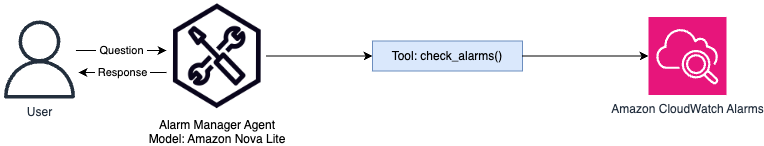

In [15]:
from IPython.display import Image
Image(filename='images/cloudwatch.png')

The simplest way to define custom tools is as a Python function with the **@tool** decorator.

13. To create a custom AWS account health tool, run the following cell:

In [16]:
from strands import tool

# Define any Python function as a tool with the @tool decorator
@tool
# Returns a string for interpretability by the agent
def alarms(alarm_name: str) -> str:
    try:
        # Two sessions to check alarms in multiple regions
        cloudwatch_use1 = use1_session.client("cloudwatch")
        cloudwatch_usw2 = usw2_session.client("cloudwatch")

        MetricAlarms = cloudwatch_use1.describe_alarms(StateValue="ALARM")["MetricAlarms"] + cloudwatch_usw2.describe_alarms(StateValue="ALARM")["MetricAlarms"]

        if not MetricAlarms:
            return "No alarms are currently in ALARM state"

        alarm_count = len(MetricAlarms)
        alarm_names = [alarm["AlarmName"] for alarm in MetricAlarms]

        # Return a descriptive string for the agent to leverage
        return f"{alarm_count} alarm{'s' if alarm_count > 1 else ''} in ALARM state: {', '.join(alarm_names)}"

    except:
        return "An error occurred checking alarm with boto3"

14. To create an agent that uses the new tool, run the following cell:

In [17]:
alarm_manager_agent = Agent(
    model=nova_lite,
    system_prompt="You are a helpful assistant that notifies when CloudWatch alarms are in alarm.",
    tools=[alarms],
    callback_handler=None
)

15. To invoke the CloudWatch alarms agent, run the following cell:

In [18]:
print(alarm_manager_agent("Are any alarms in my account IN ALARM?"))

<thinking>The tool has indicated that there is at least one alarm in the ALARM state. I should inform the user about the specific alarm that is in the ALARM state.</thinking>

There is at least one alarm in your account that is currently in the ALARM state. The alarm "Client-System-Down" is in the ALARM state. You may want to investigate and address this issue.



<div style="background-color: rgba(231, 243, 237, 0.3); border: 1px solid #43A047; border-radius: 6px; padding: 15px; margin: 10px 0; color: #2E7D32; font-family: monospace; max-width: 100%; word-wrap: break-word; box-sizing: border-box;">
<strong>Example Output</strong>
<br><br>
There is currently 1 alarm in the ALARM state: "Client-System-Down".
</div>

There is an alarm indicating an issue with a client system in an AnyCompany AWS account.

### Task 1.5: Add web search capabilities to an agent

Use a Python library in a custom Python tool to let your agent browse the web.

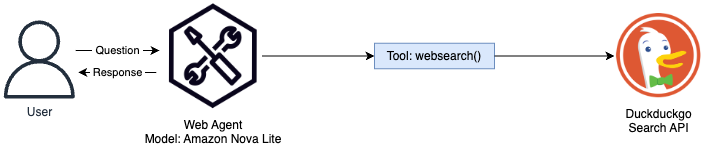

In [19]:
from IPython.display import Image
Image(filename='images/web agent.png')

The DuckDuckGo Search (DDGS) library makes allow you to use a search engine in Python code. It is one solution to circumventing LLM training cutoffs and getting an alternative source for information.

16. To create a custom tool for performing web searches, run the following cell:

In [20]:
from ddgs import DDGS
from ddgs.exceptions import RatelimitException, DDGSException
import logging

# Configure logging
logging.getLogger("strands").setLevel(logging.INFO)

# Define a websearch tool
@tool
def websearch(keywords: str, region: str = "us-en", max_results: int | None = None) -> str:
    """Search the web to get updated information.
    Args:
        keywords (str): The search query keywords.
        region (str): The search region: wt-wt, us-en, uk-en, ru-ru, etc..
        max_results (int | None): The maximum number of results to return.
    Returns:
        List of dictionaries with search results.
    """
    try:
        results = DDGS().text(keywords, region=region, max_results=max_results)
        return results if results else "No results found."
    except RatelimitException:
        return "RatelimitException: Please try again after a short delay."
    except DDGSException as d:
        return f"DuckDuckGoSearchException: {d}"
    except Exception as e:
        return f"Exception: {e}"

17. To create a researcher agent, run the following cell:

In [21]:
# Create a research assistant agent
researcher_agent = Agent(
    model=nova_lite, 
    system_prompt="""You are a technology research assistant.
    Use the websearch tool to find up to date information, announcments, and documentation""",
    # Import the websearch tool created above
    tools=[websearch],
)

**Note:** With Strands Agents, it's important to tell the agent when and how to use tools to get predictable agent responses.

18. To find out about the newest innovations in generative AI, run the following cell:

In [22]:
print(researcher_agent("What are the newest GenAI innovations in 2025?"))

<thinking> The User is asking for the newest GenAI innovations in 2025. Since I do not have access to information beyond 2023, I will need to use the websearch tool to find the most recent information available on GenAI innovations as of 2025. I will search for announcements, articles, and documentation that discuss the latest developments in GenAI from reputable sources. </thinking>

Tool #1: websearch
<thinking> Based on the search results, here are the newest GenAI innovations in 2025:

1. Multimodal Abilities: The newest version of Generative AI tools includes fresh tools like OpenAI's GPT-4 and Google's Gemini 2.0 bringing several important upgrades, such as handling not just text ‒ but also images, audios and videos ‒ making them more adaptable.

2. AI agents and AI-ready data: These are the two fastest advancing technologies on the 2025 Gartner Hype Cycle for Artificial Intelligence, according to Gartner.

3. Generative AI Evolutions: 2025's generative AI breakthroughs include m

<div style="background-color: rgba(231, 243, 237, 0.3); border: 1px solid #43A047; border-radius: 6px; padding: 15px; margin: 10px 0; color: #2E7D32; font-family: monospace; max-width: 100%; word-wrap: break-word; box-sizing: border-box;">
<strong>Example Output</strong>
<br><br>
Tool #2: websearch
<thinking>Based on the search results, here are some of the newest GenAI innovations in 2025:</thinking>

- **Self-Supervised Learning:** Innovations like self-supervised learning, which reduces the need for large amounts of labeled training data, provide solutions to practical problems in the GenAI space.
- **New Use Cases:** In 2025, several new use cases will emerge for GenAI, beyond chatbots and image generators.

...
</div>

**Note:** Before proceeding, make sure **project/flight.csv** exists and is correctly formatted or future lab steps may not work correctly.

19. Return to the lab instructions and continue with the **Task 2** section.